1. Load the dataset into a Pandas DataFrame

In [54]:
import numpy as np
import pandas as pd
from pathlib import Path
csv_path = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(csv_path)

2. Use structural inspection methods (head(), info(), describe()) to analyze features such as tenure, MonthlyCharges, TotalCharges, Contract, and PaymentMethod.

In [55]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [56]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


3. Drop any non-informative identifiers (such as customerID).

In [58]:
df = df.drop(columns=["customerID"])
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

4. Quantify any missing or implicit missing values across the columns (handling whitespace strings in TotalCharges) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.



In [59]:

from sklearn.impute import SimpleImputer
whitespace = df["TotalCharges"].astype(str).str.strip() == ""
df.loc[whitespace, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True).astype(float)
num_imputer = SimpleImputer(strategy="median")
df["TotalCharges"] = num_imputer.fit_transform(df[["TotalCharges"]])
remaining = df.isna().sum()
print(f"\nImputed median value used: {num_imputer.statistics_[0]:.2f}")


Imputed median value used: 1397.47


5. Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

In [60]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn"])

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features),])

print("\nColumnTransformer w/", len(numerical_features), "numerical and",
      len(categorical_features), "categorical features.")


ColumnTransformer w/ 4 numerical and 15 categorical features.


6. Append an SGDClassifier configured with loss='log_loss' to the end of your pipeline to perform logistic regression and enable probability estimation.

In [61]:
from sklearn.linear_model import SGDClassifier
full_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(loss="log_loss", random_state=42, max_iter=1000, tol=1e-3)),
])

7. Split your dataset into training and test sets using 3 different train/test split ratios (for example, 80/20, 70/30, and 60/40), fit your complete pipeline on each configuration, and evaluate performance using a confusion matrix, classification report, and ROC-AUC curve. Report on any performance differences detected across the various splitting ratios.

Split: 80/20
Train size: 5634, Test size: 1409

Confusion Matrix:
[[940  95]
 [208 166]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.91      0.86      1035
       Churn       0.64      0.44      0.52       374

    accuracy                           0.78      1409
   macro avg       0.73      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409

ROC-AUC: 0.8296


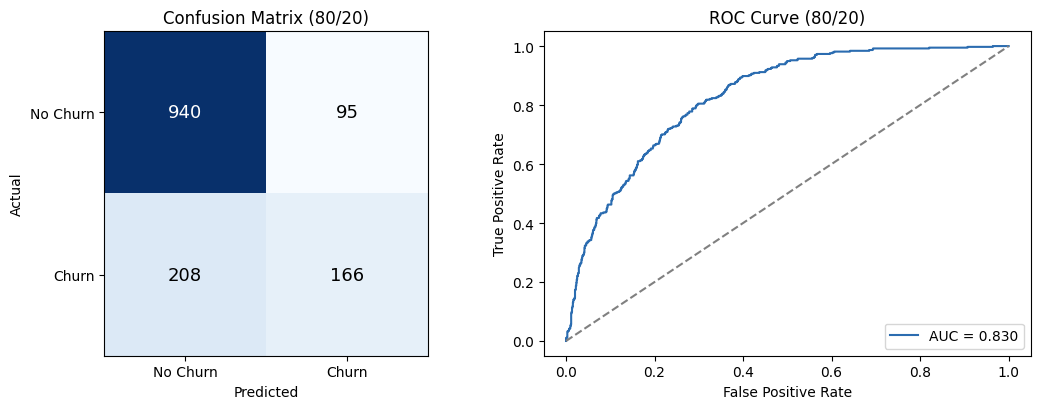

In [62]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                              roc_auc_score, roc_curve)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(loss="log_loss", random_state=42, max_iter=1000, tol=1e-3)),
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
print(f"Split: {int((1-0.2)*100)}/{int(0.2*100)}")
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}\n")
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC: {auc:.4f}")

fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("Confusion Matrix (80/20)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["No Churn", "Churn"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["No Churn", "Churn"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=13)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}", color="#2b6cb0")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (80/20)")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

Split: 70/30
Train size: 4930, Test size: 2113

Confusion Matrix:
[[1388  164]
 [ 259  302]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.87      1552
       Churn       0.65      0.54      0.59       561

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.73      2113
weighted avg       0.79      0.80      0.79      2113

ROC-AUC: 0.8420


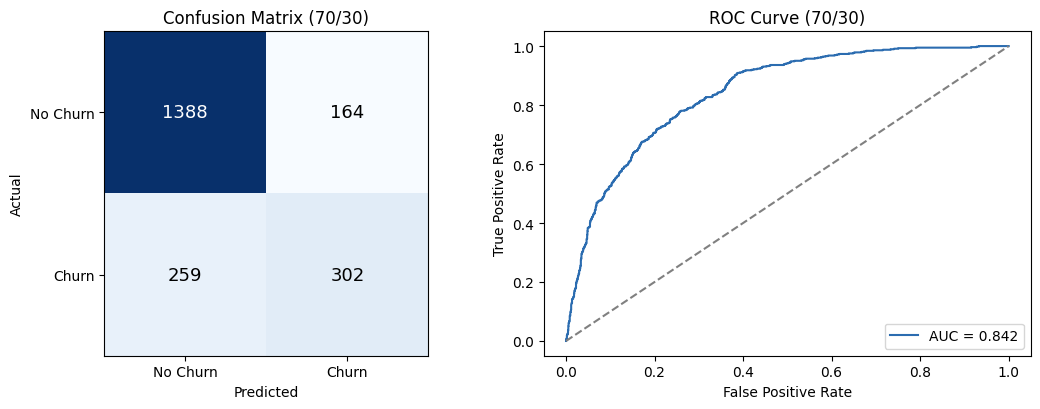

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

pipe = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(loss="log_loss", random_state=42, max_iter=1000, tol=1e-3)),
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
print(f"Split: {int((1-0.3)*100)}/{int(0.3*100)}")
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}\n")
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC: {auc:.4f}")

fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("Confusion Matrix (70/30)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["No Churn", "Churn"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["No Churn", "Churn"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=13)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}", color="#2b6cb0")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (70/30)")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

Split: 60/40
Train size: 4225, Test size: 2818

Confusion Matrix:
[[1763  307]
 [ 291  457]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.85      0.85      2070
       Churn       0.60      0.61      0.60       748

    accuracy                           0.79      2818
   macro avg       0.73      0.73      0.73      2818
weighted avg       0.79      0.79      0.79      2818

ROC-AUC: 0.8347


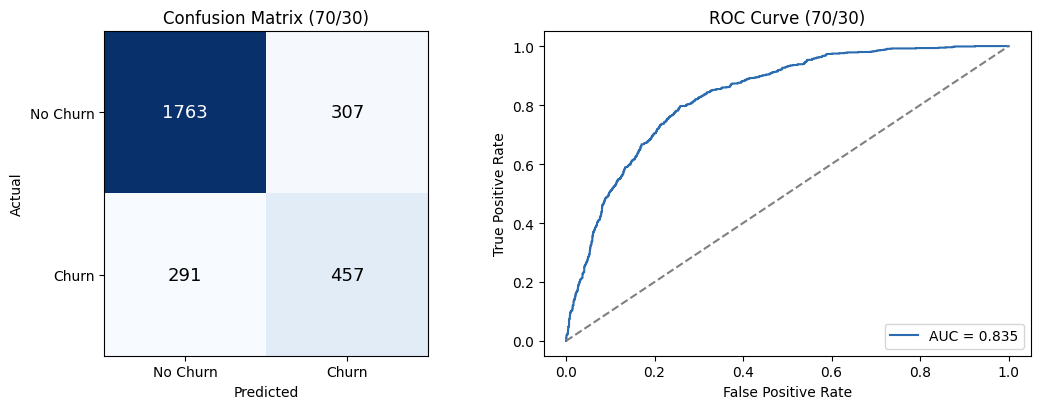

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

pipe = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(loss="log_loss", random_state=42, max_iter=1000, tol=1e-3)),
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
print(f"Split: {int((1-0.4)*100)}/{int(0.4*100)}")
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}\n")
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC: {auc:.4f}")

fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("Confusion Matrix (70/30)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["No Churn", "Churn"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["No Churn", "Churn"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=13)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}", color="#2b6cb0")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (70/30)")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Report**: Performance was stable across all three splits, with accuracy ranging only from 0.78 to 0.80 and ROC-AUC from 0.836 to 0.844. The 70/30 split performed best overall, posting the highest accuracy (0.80), ROC-AUC (0.8439), and churn recall (0.49), while 80/20 had similar accuracy but caught far fewer actual churners (recall 0.29).

8. Generate a 2D decision boundary visualization or inspect model feature coefficients to interpret how the model separates churning customers from retained customers.

In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
final_pipe = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", SGDClassifier(loss="log_loss", random_state=42, max_iter=1000, tol=1e-3)),
])
final_pipe.fit(X_train, y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 SGDClassifier(loss='log_loss', random_state=42))])

In [66]:
ohe = final_pipe.named_steps["preprocessing"].named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe.get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([numerical_features, cat_feature_names])
coefs = final_pipe.named_steps["classifier"].coef_[0]

coef_series = pd.Series(coefs, index=all_feature_names).sort_values()
print("Top 10 features pushing toward CHURN:")
print(coef_series.sort_values(ascending=False).head(10))
print("\nTop 10 features pushing toward RETENTION:")
print(coef_series.head(10))

Top 10 features pushing toward CHURN:
InternetService_Fiber optic    1.367301
Contract_Month-to-month        1.086067
PaperlessBilling_Yes           0.867345
StreamingTV_Yes                0.859386
StreamingMovies_Yes            0.835596
TechSupport_No                 0.649890
Partner_Yes                    0.602662
MultipleLines_Yes              0.582182
OnlineBackup_No                0.574812
PhoneService_Yes               0.573032
dtype: float64

Top 10 features pushing toward RETENTION:
tenure                                  -1.218762
MonthlyCharges                          -1.159272
InternetService_DSL                     -0.513085
Contract_Two year                       -0.477641
PaymentMethod_Credit card (automatic)   -0.050909
MultipleLines_No                        -0.009149
StreamingTV_No                          -0.005170
StreamingMovies_No                       0.018620
PaperlessBilling_No                      0.032333
DeviceProtection_No internet service     0.045462
dtyp

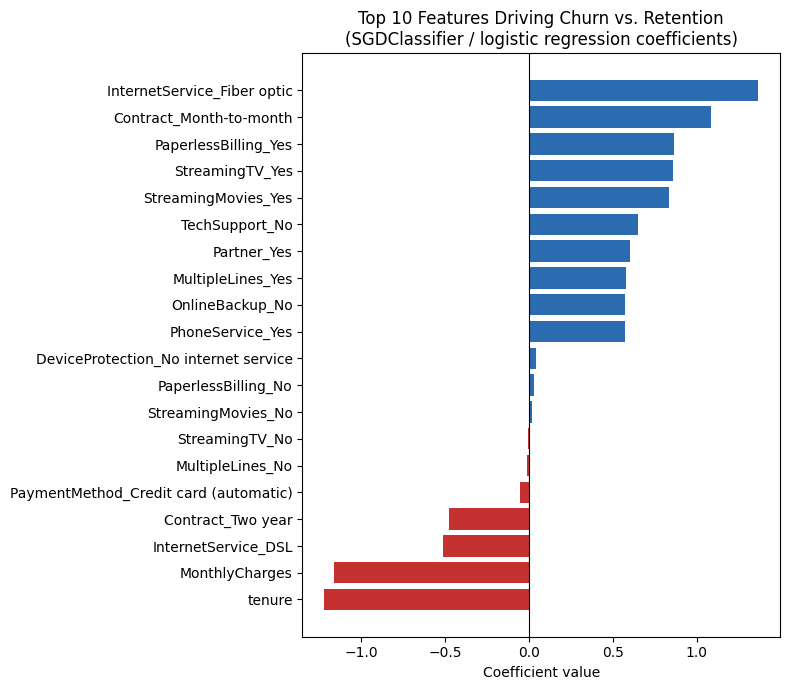

In [67]:
top_pos = coef_series.sort_values(ascending=False).head(10)
top_neg = coef_series.head(10)
plot_data = pd.concat([top_neg, top_pos]).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#c53030" if v < 0 else "#2b6cb0" for v in plot_data.values]
ax.barh(plot_data.index, plot_data.values, color=colors)
ax.set_title("Top 10 Features Driving Churn vs. Retention\n(SGDClassifier / logistic regression coefficients)")
ax.set_xlabel("Coefficient value")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [68]:
X2 = df[["tenure", "MonthlyCharges"]].values
y2 = y.values
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)
scaler2 = StandardScaler().fit(X2_train)
X2_train_s = scaler2.transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

clf2 = SGDClassifier(loss="log_loss", random_state=42, max_iter=1000, tol=1e-3)
clf2.fit(X2_train_s, y2_train)
acc2 = clf2.score(X2_test_s, y2_test)
print("Illustrative 2-feature model (tenure, MonthlyCharges) test accuracy:", round(acc2, 4))

Illustrative 2-feature model (tenure, MonthlyCharges) test accuracy: 0.7864


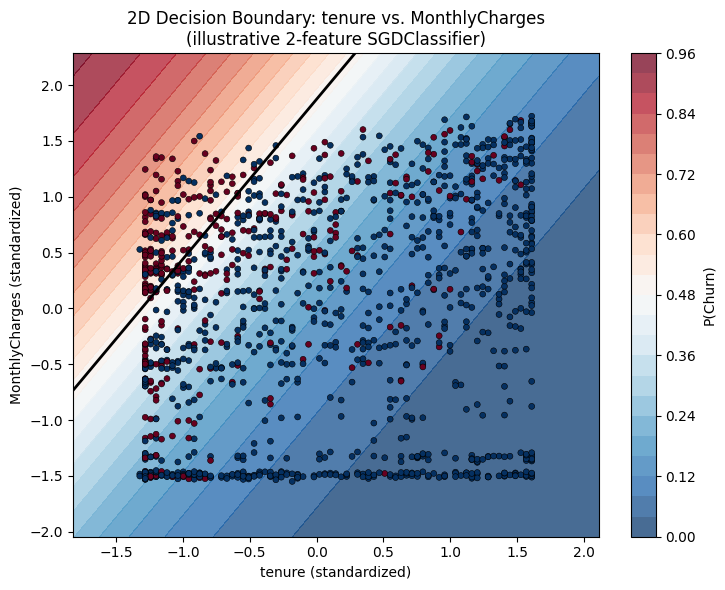

In [69]:
xx, yy = np.meshgrid(
    np.linspace(X2_train_s[:, 0].min() - 0.5, X2_train_s[:, 0].max() + 0.5, 300),
    np.linspace(X2_train_s[:, 1].min() - 0.5, X2_train_s[:, 1].max() + 0.5, 300),
)
Z = clf2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7.5, 6))
cs = ax.contourf(xx, yy, Z, levels=25, cmap="RdBu_r", alpha=0.75)
plt.colorbar(cs, ax=ax, label="P(Churn)")
ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=2)
ax.scatter(X2_test_s[:, 0], X2_test_s[:, 1], c=y2_test, cmap="RdBu_r",
           edgecolor="k", s=18, linewidth=0.4)
ax.set_xlabel("tenure (standardized)")
ax.set_ylabel("MonthlyCharges (standardized)")
ax.set_title("2D Decision Boundary: tenure vs. MonthlyCharges\n(illustrative 2-feature SGDClassifier)")
plt.tight_layout()
plt.show()